# Analog modulation

One voice-like message through AM, FM, PM and SSB: modulate to complex
baseband, add noise and a neighbouring signal, demodulate through a channel
filter, and compare spectra and recovered messages.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

import sigline as sl

fs = 48_000.0
taps = 201

## The link

Message: two tones (500 Hz and 1.3 kHz). Channel: noise and a neighbour 12
kHz away. Each scheme gets a channel filter wide enough for its signal.
Modulators and demodulators are functions that return subsystems of
library blocks; FM and the channel filters need `fs` to set up their
scales and taps.

In [2]:
schemes = {
    "AM": (sl.am_mod(0.5), sl.am_demod(0.5, channel_width=6e3, taps=taps, fs=fs)),
    "FM": (
        sl.fm_mod(3e3, fs=fs),
        sl.fm_demod(3e3, channel_width=14e3, taps=taps, fs=fs),
    ),
    "PM": (sl.pm_mod(1.5), sl.pm_demod(1.5, channel_width=14e3, taps=taps, fs=fs)),
    "SSB": (sl.ssb_mod(), sl.ssb_demod(channel_width=3e3, taps=taps, fs=fs)),
}
rx_spec, audio, links = {}, {}, {}
for name, (mod, demod) in schemes.items():
    msg = 0.5 * sl.Sine(500.0) + 0.4 * sl.Sine(1300.0)
    tx = msg >> mod
    neighbour = 0.3 * sl.Sine(12e3, complex=True)
    rx = tx + sl.Noise(0.01, seed=1, complex=True) + neighbour
    rx_spec[name] = sl.SpectrumAnalyzer(nfft=1024, name=name)
    audio[name] = sl.Scope(name, keep=2400)
    rx >> rx_spec[name]
    rx >> demod >> audio[name]
    links[name] = sl.Diagram(audio[name], fs=fs)
    links[name].run(1.0)

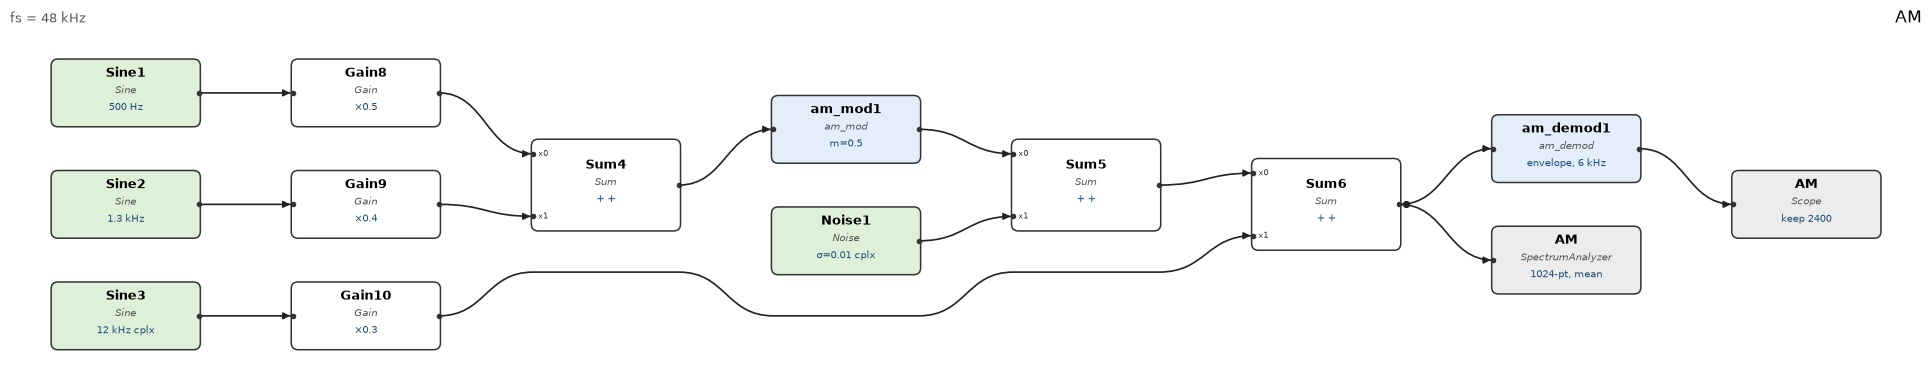

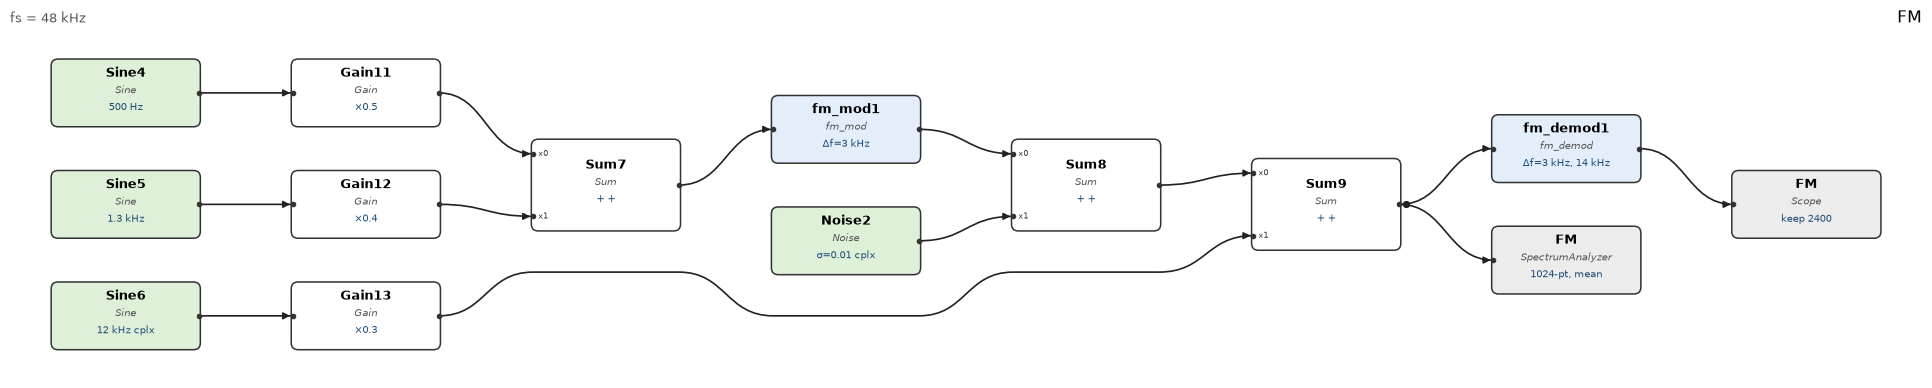

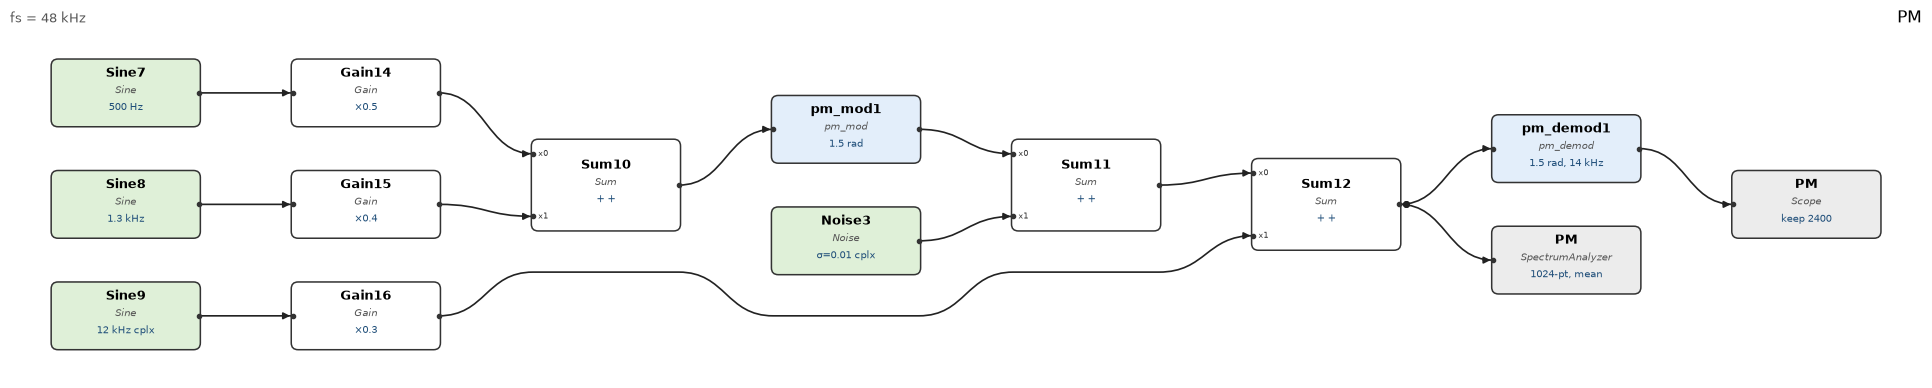

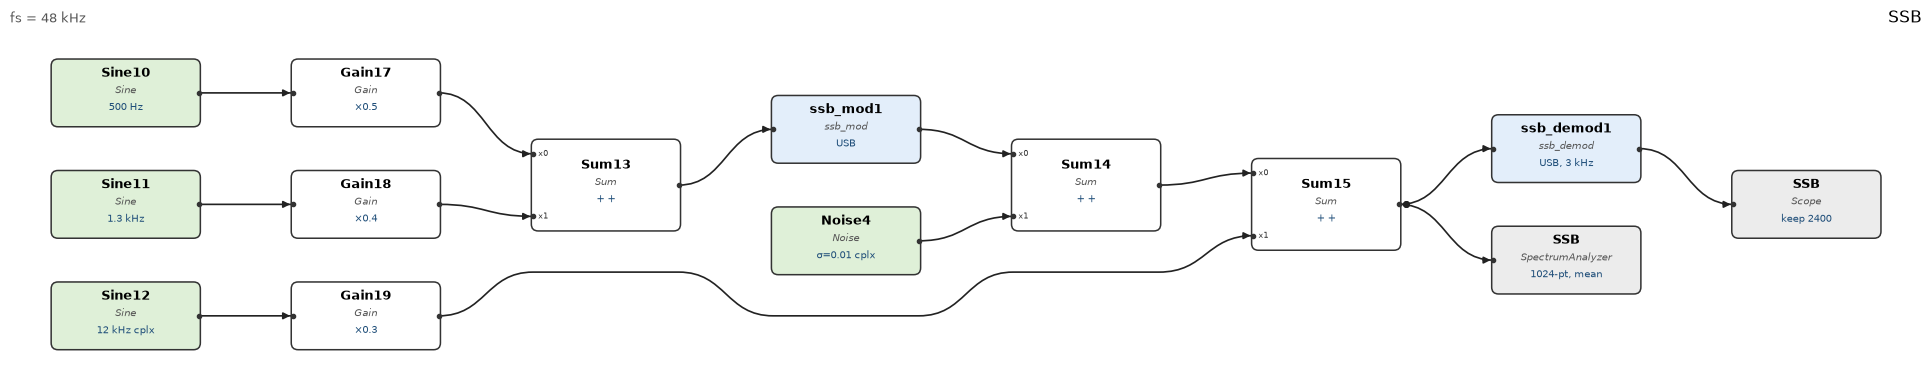

In [3]:
for name, d in links.items():
    d.draw()
    plt.title(name, loc="right")
    plt.show()

Each modulator and demodulator is one box above, and a subsystem of
library blocks inside. The FM demodulator is a channel filter, a
discriminator comparing each sample with the previous one, and a scale:

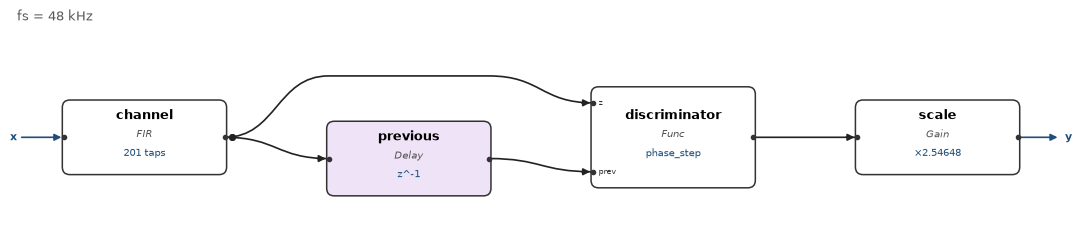

members: ['fm_demod1/channel', 'fm_demod1/previous', 'fm_demod1/discriminator', 'fm_demod1/scale']
scale: 2.5465 = fs / (2 pi deviation)


In [4]:
fm_demod = schemes["FM"][1]
fm_demod.draw()
plt.show()
print(f"members: {[m.name for m in fm_demod.members]}")
print(f"scale: {fm_demod.scale.g:.4f} = fs / (2 pi deviation)")

The SSB modulator: the message delayed and, Hilbert transformed, rotated
by `j`, summed.

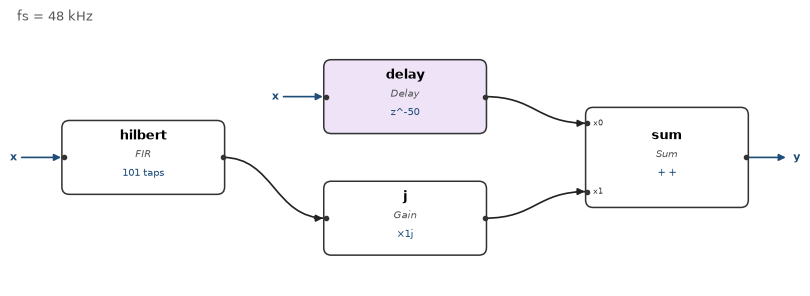

In [5]:
schemes["SSB"][0].draw()
plt.show()

## Spectra at the receiver input

AM shows the carrier and two sidebands, FM and PM spread wider, SSB uses one
side only. The neighbour sits at +12 kHz.

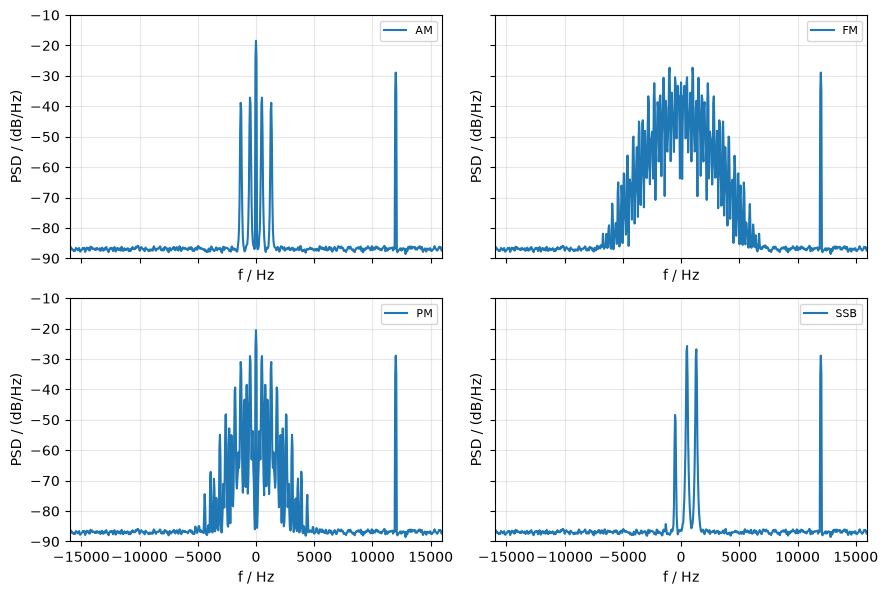

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(9, 6), sharex=True, sharey=True)
for ax, sa in zip(axes.flat, rx_spec.values(), strict=True):
    sa.plot(ax=ax, max_hold=False)
    ax.set_xlim(-16e3, 16e3)
    ax.set_ylim(-90, -10)
fig.tight_layout()
plt.show()

## Recovered messages

The last 50 ms against the message, delayed by the channel filter's
`(taps - 1) / 2` samples (SSB also by its Hilbert filter, FM by one sample:
its phase integrates the message up to the sample before). PM and FM swap
noise for bandwidth; SSB needs the least.

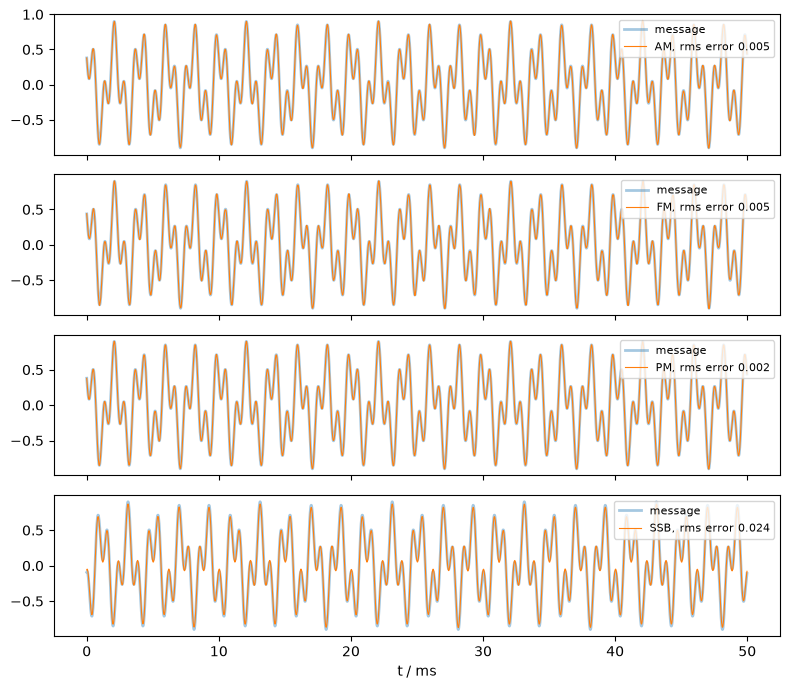

In [7]:
t = np.arange(2400) / fs
n0 = int(fs) - 2400
fig, axes = plt.subplots(4, 1, figsize=(8, 7), sharex=True)
for ax, (name, sc) in zip(axes, audio.items(), strict=True):
    # the channel filter; SSB also its Hilbert filter, FM its integrator
    delay = (taps - 1) // 2 + {"SSB": (101 - 1) // 2, "FM": 1}.get(name, 0)
    n = np.arange(n0, n0 + 2400) - delay
    ref = 0.5 * np.cos(2 * np.pi * 500 * n / fs) + 0.4 * np.cos(
        2 * np.pi * 1300 * n / fs
    )
    err = np.sqrt(np.mean((sc.data - ref) ** 2))
    ax.plot(1e3 * t, ref, lw=2, alpha=0.4, label="message")
    ax.plot(1e3 * t, sc.data, lw=0.8, label=f"{name}, rms error {err:.3f}")
    ax.legend(loc="upper right", fontsize=8)
axes[-1].set_xlabel("t / ms")
fig.tight_layout()
plt.show()

## Summary

- `am_mod`/`am_demod`, `fm_mod`/`fm_demod`, `pm_mod`/`pm_demod`,
  `ssb_mod`/`ssb_demod`: subsystems of library blocks, with named inner
  blocks (`demod.scale.g`).
- Modulators give complex baseband; demodulators take an optional
  `channel_width` and filter before detecting.